## This is an attempt to create a language model using just low rank matrices

Since pretrained models are low rank and sparse (Li et al., 2023) and that most nns can do fine without 80% - 90% of their weights (Frankle & Carbin, 2019) I am attempting to train a neural network using only low rank approximations of all linear layers.

---

The first part is an analysis of the rank of linear layers of standard petrained models.

In [12]:
import torch
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM
import gc
import numpy as np
import re
import time
import json
import os

def matrix_rank_with_tolerance(tensor, tolerance_factor=1.0):
    """
    Compute the rank of a PyTorch tensor matrix with a variable tolerance factor.
    
    Args:
        tensor (torch.Tensor): The input tensor.
        tolerance_factor (float): Multiplier for the default tolerance. 
                                Higher values result in lower estimated ranks.
    
    Returns:
        tuple: (rank, singular_values, tolerance_used)
    """
    if tensor.dim() != 2:
        raise ValueError(f"Expected a 2D tensor, got tensor with {tensor.dim()} dimensions")
    
    # Convert to float32 if tensor is in half precision
    if tensor.dtype == torch.float16 or tensor.dtype == torch.half:
        tensor = tensor.to(torch.float32)
    
    # Compute the SVD
    with torch.no_grad():
        singular_values = torch.linalg.svdvals(tensor)
    
    # Compute default tolerance and apply the factor
    default_tol = singular_values.max() * max(tensor.size()) * torch.finfo(tensor.dtype).eps
    actual_tol = default_tol * tolerance_factor
    
    # Count the number of singular values greater than tolerance
    rank = torch.sum(singular_values > actual_tol).item()
    
    return rank, singular_values.cpu().numpy(), actual_tol

def analyze_with_multiple_tolerances(model_name="Qwen/Qwen2.5-1.5B-Instruct", 
                                   batch_size=5,
                                   tolerance_factors=[0.1, 1.0, 10.0, 100.0],
                                   results_dir="rank_analysis_results"):
    """
    Analyze all linear layers with multiple tolerance factors.
    
    Args:
        model_name: Name or path of the model to analyze
        batch_size: Number of layers to process before clearing memory
        tolerance_factors: List of tolerance factors to try
        results_dir: Directory to save results
        
    Returns:
        Dictionary with analysis results for each tolerance factor
    """
    # Create results directory if it doesn't exist
    os.makedirs(results_dir, exist_ok=True)
    print(f"Saving results to directory: {results_dir}")
    
    print(f"Loading model: {model_name}")
    start_time = time.time()
    
    # Try loading the model
    try:
        model = AutoModelForCausalLM.from_pretrained(
            model_name,
            torch_dtype=torch.float16
        )
        print("Model loaded successfully")
    except Exception as e:
        print(f"Error loading model: {str(e)}")
        return None
    
    # Collect all linear layers
    linear_layers = []
    print("Collecting all linear layers...")
    for name, module in model.named_modules():
        if isinstance(module, torch.nn.Linear):
            linear_layers.append((name, module))
    
    total_layers = len(linear_layers)
    print(f"Found {total_layers} linear layers to analyze")
    
    # Create batches
    batches = [linear_layers[i:i + batch_size] for i in range(0, len(linear_layers), batch_size)]
    print(f"Processing in {len(batches)} batches of up to {batch_size} layers each")
    
    # Initialize results dictionary - organized by tolerance factor
    all_results = {factor: {} for factor in tolerance_factors}
    
    # Track singular value distributions for histogram
    sv_sample_layers = {}
    
    # Process each batch
    for batch_idx, batch in enumerate(batches):
        print(f"\nProcessing batch {batch_idx+1}/{len(batches)}")
        
        # Process each layer in the batch
        for idx, (name, module) in enumerate(batch):
            print(f"Processing layer {idx+1}/{len(batch)}: {name}")
            try:
                # Access the weight directly
                weight = module.weight
                
                # Get matrix dimensions
                out_features, in_features = weight.shape
                full_rank = min(out_features, in_features)
                
                # Identify layer type
                layer_type = "other"
                if 'q_proj' in name:
                    layer_type = "attention_q"
                elif 'k_proj' in name:
                    layer_type = "attention_k"
                elif 'v_proj' in name:
                    layer_type = "attention_v"
                elif 'o_proj' in name:
                    layer_type = "attention_o"
                elif 'up_proj' in name or 'intermediate' in name or 'fc1' in name:
                    layer_type = "ffn_up"
                elif 'down_proj' in name or 'output' in name or 'fc2' in name:
                    layer_type = "ffn_down"
                
                # Extract layer number if possible
                layer_num = None
                match = re.search(r'layers\.(\d+)', name)
                if match:
                    layer_num = int(match.group(1))
                
                # Store basic layer info
                layer_info = {
                    'layer_type': layer_type,
                    'layer_num': layer_num,
                    'out_features': int(out_features),
                    'in_features': int(in_features),
                    'full_rank': int(full_rank),
                    'ranks': {},
                    'ratios': {}
                }
                
                # Compute rank with each tolerance factor
                for factor in tolerance_factors:
                    rank, singular_values, tol_used = matrix_rank_with_tolerance(weight, factor)
                    ratio = rank / full_rank
                    
                    # Store rank and ratio for this tolerance factor
                    layer_info['ranks'][str(factor)] = int(rank)
                    layer_info['ratios'][str(factor)] = float(ratio)
                    
                    # Store tolerance used
                    if 'tolerances' not in layer_info:
                        layer_info['tolerances'] = {}
                    layer_info['tolerances'][str(factor)] = float(tol_used)
                    
                    print(f"  Tolerance factor {factor:.1f}: Rank {rank}/{full_rank} = {ratio:.4f}")
                
                # For some representative layers, save singular value distributions
                # Sample one layer from each type and position (early, middle, late)
                is_sampled = False
                if layer_type not in sv_sample_layers and len(sv_sample_layers) < 6:
                    sv_sample_layers[name] = singular_values
                    is_sampled = True
                elif layer_type in ['attention_q', 'ffn_up'] and layer_num is not None:
                    if layer_num == 0 and f"{layer_type}_early" not in sv_sample_layers:
                        sv_sample_layers[f"{layer_type}_early"] = singular_values
                        is_sampled = True
                    elif layer_num == model.config.num_hidden_layers // 2 and f"{layer_type}_middle" not in sv_sample_layers:
                        sv_sample_layers[f"{layer_type}_middle"] = singular_values
                        is_sampled = True
                    elif layer_num == model.config.num_hidden_layers - 1 and f"{layer_type}_late" not in sv_sample_layers:
                        sv_sample_layers[f"{layer_type}_late"] = singular_values
                        is_sampled = True
                
                if is_sampled:
                    print(f"  Sampled singular values for visualization")
                
                # Update results for each tolerance factor
                for factor in tolerance_factors:
                    all_results[factor][name] = layer_info
                    
            except Exception as e:
                print(f"Error analyzing layer {name}: {str(e)}")
        
        # Save interim results after each batch
        interim_filename = os.path.join(results_dir, f"interim_batch_{batch_idx+1}.json")
        with open(interim_filename, 'w') as f:
            json.dump(all_results, f, indent=2)
        print(f"Saved interim results to {interim_filename}")
        
        # Print batch summary
        print("Batch summary:")
        for factor in tolerance_factors:
            batch_ratios = [all_results[factor][name]['ratios'][str(factor)] 
                           for name in [n for n, _ in batch] if name in all_results[factor]]
            if batch_ratios:
                avg_batch_ratio = sum(batch_ratios) / len(batch_ratios)
                print(f"  Tolerance factor {factor:.1f}: Avg ratio {avg_batch_ratio:.4f}")
        
        # Force garbage collection between batches
        gc.collect()
        torch.cuda.empty_cache() if torch.cuda.is_available() else None
    
    # Save singular value distributions
    if sv_sample_layers:
        sv_filename = os.path.join(results_dir, "singular_value_samples.json")
        sv_data = {name: values.tolist() for name, values in sv_sample_layers.items()}
        with open(sv_filename, 'w') as f:
            json.dump(sv_data, f)
        print(f"Saved singular value samples to {sv_filename}")
    
    # Free model memory
    del model
    gc.collect()
    torch.cuda.empty_cache() if torch.cuda.is_available() else None
    
    # Save final results
    final_filename = os.path.join(results_dir, "complete_results.json")
    with open(final_filename, 'w') as f:
        json.dump(all_results, f, indent=2)
    print(f"Saved complete results to {final_filename}")
    
    # Write model info to a text file
    model_info_filename = os.path.join(results_dir, "model_info.txt")
    with open(model_info_filename, 'w') as f:
        f.write(f"Model: {model_name}\n")
        f.write(f"Analysis date: {time.strftime('%Y-%m-%d %H:%M:%S')}\n")
        f.write(f"Tolerance factors: {tolerance_factors}\n")
        f.write(f"Total layers analyzed: {total_layers}\n")
        f.write(f"Batch size: {batch_size}\n")
        f.write(f"Total analysis time: {time.time() - start_time:.2f} seconds\n")
    
    # Print total time
    elapsed_time = time.time() - start_time
    print(f"Total analysis time: {elapsed_time:.2f} seconds")
    
    return all_results

def visualize_tolerance_comparison(results_file=None, results_dir="rank_analysis_results"):
    """
    Create visualizations comparing results with different tolerance factors.
    
    Args:
        results_file: Path to the JSON file with analysis results
        results_dir: Directory where results are stored
    """
    # If no specific file is provided, use the default one in the results directory
    if results_file is None:
        results_file = os.path.join(results_dir, "complete_results.json")
    
    # Make sure the results directory exists
    os.makedirs(results_dir, exist_ok=True)
    
    # Load results from file
    try:
        with open(results_file, 'r') as f:
            results = json.load(f)
        print(f"Loaded results with {len(results)} tolerance factors")
    except Exception as e:
        print(f"Error loading results: {str(e)}")
        return
    
    tolerance_factors = sorted([float(factor) for factor in results.keys()])
    print(f"Tolerance factors: {tolerance_factors}")
    
    # Analyze overall rank ratio by tolerance factor
    overall_avg_ratios = []
    overall_avg_ranks = []
    
    for factor in tolerance_factors:
        factor_str = str(factor)
        all_ratios = []
        all_ranks = []
        
        for layer_name, layer_data in results[factor_str].items():
            ratio = layer_data['ratios'][factor_str]
            rank = layer_data['ranks'][factor_str]
            
            all_ratios.append(ratio)
            all_ranks.append(rank / layer_data['full_rank'])  # Normalize ranks
        
        overall_avg_ratios.append(sum(all_ratios) / len(all_ratios) if all_ratios else 0)
        overall_avg_ranks.append(sum(all_ranks) / len(all_ranks) if all_ranks else 0)
    
    # Plot 1: Average rank ratio by tolerance factor
    plt.figure(figsize=(12, 8))
    plt.plot(tolerance_factors, overall_avg_ratios, 'o-', linewidth=2, markersize=8)
    plt.xscale('log')  # Log scale for tolerance factors
    
    for i, (factor, ratio) in enumerate(zip(tolerance_factors, overall_avg_ratios)):
        plt.text(factor, ratio + 0.01, f"{ratio:.4f}", ha='center', va='bottom')
    
    plt.xlabel('Tolerance Factor (log scale)')
    plt.ylabel('Average Rank Ratio')
    plt.title('Average Rank Ratio vs. Tolerance Factor')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(results_dir, 'rank_ratio_by_tolerance.png'), dpi=300, bbox_inches='tight')
    plt.show()
    
    # Plot 2: Average rank ratio by layer type for each tolerance factor
    plt.figure(figsize=(14, 8))
    
    # Group by layer type
    type_ratios = {}
    
    for factor in tolerance_factors:
        factor_str = str(factor)
        layer_types = {}
        
        for layer_name, layer_data in results[factor_str].items():
            layer_type = layer_data['layer_type']
            
            if layer_type not in layer_types:
                layer_types[layer_type] = []
            
            layer_types[layer_type].append(layer_data['ratios'][factor_str])
        
        # Calculate average ratio by type
        type_avg_ratios = {}
        for layer_type, ratios in layer_types.items():
            if ratios:
                type_avg_ratios[layer_type] = sum(ratios) / len(ratios)
        
        type_ratios[factor] = type_avg_ratios
    
    # Prepare data for grouped bar chart
    layer_types = sorted(set().union(*[d.keys() for d in type_ratios.values()]))
    
    # Define colors for each layer type
    type_colors = {
        'attention_q': 'royalblue',
        'attention_k': 'cornflowerblue',
        'attention_v': 'lightblue',
        'attention_o': 'steelblue',
        'ffn_up': 'salmon',
        'ffn_down': 'tomato',
        'other': 'gray'
    }
    
    # Set width of bars
    bar_width = 0.8 / len(tolerance_factors)
    
    # Set position of bars on x axis
    positions = np.arange(len(layer_types))
    
    # Plot bars
    for i, factor in enumerate(tolerance_factors):
        values = [type_ratios[factor].get(t, 0) for t in layer_types]
        offset = i - (len(tolerance_factors) - 1) / 2
        pos = positions + offset * bar_width
        
        plt.bar(pos, values, bar_width, 
                label=f'Tolerance={factor}', 
                alpha=0.7)
    
    # Add labels, title and legend
    plt.xlabel('Layer Type')
    plt.ylabel('Average Rank Ratio')
    plt.title('Average Rank Ratio by Layer Type for Different Tolerance Factors')
    plt.xticks(positions, [t.replace('_', ' ').title() for t in layer_types], rotation=45)
    plt.legend(title='Tolerance Factor')
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(results_dir, 'rank_ratio_by_type_and_tolerance.png'), dpi=300, bbox_inches='tight')
    plt.show()
    
    # Plot 3: Singular value distribution if available
    try:
        sv_file = os.path.join(results_dir, "singular_value_samples.json")
        with open(sv_file, 'r') as f:
            sv_data = json.load(f)
        
        if sv_data:
            plt.figure(figsize=(14, 10))
            
            # Plot for each sampled layer
            for i, (name, values) in enumerate(sv_data.items()):
                plt.subplot(len(sv_data), 1, i+1)
                
                # Convert to numpy array
                values = np.array(values)
                
                # Sort values in descending order
                values = np.sort(values)[::-1]
                
                # Normalize values
                values = values / values.max()
                
                # Plot singular values on log scale
                plt.semilogy(range(1, len(values)+1), values)
                
                # Add horizontal lines for different tolerance factors
                for factor in tolerance_factors:
                    # Estimate the tolerance used
                    est_tol = values.max() * factor * 1e-7  # Approximate machine epsilon
                    plt.axhline(y=est_tol, linestyle='--', alpha=0.5, 
                               label=f'Tol factor={factor}')
                
                # Make shorter name for display
                display_name = name.split('.')[-3:] if '.' in name else name
                if isinstance(display_name, list):
                    display_name = '.'.join(display_name)
                
                plt.title(f'Singular Value Distribution: {display_name}')
                plt.xlabel('Index')
                plt.ylabel('Normalized Singular Value')
                plt.grid(True, alpha=0.3)
                
                if i == 0:  # Only add legend to first subplot
                    plt.legend()
            
            plt.tight_layout()
            plt.savefig(os.path.join(results_dir, 'singular_value_distributions.png'), dpi=300, bbox_inches='tight')
            plt.show()
            
    except Exception as e:
        print(f"Could not plot singular value distributions: {str(e)}")
    
    return plt

# Example usage:
# 1. Run the analysis with multiple tolerance factors:
# results = analyze_with_multiple_tolerances(
#     "Qwen/Qwen2.5-1.5B-Instruct", 
#     batch_size=5,
#     tolerance_factors=[0.1, 1.0, 10.0, 100.0],
#     results_dir="rank_analysis_results"
# )
#
# 2. Visualize the results:
# visualize_tolerance_comparison(results_dir="rank_analysis_results")

Saving results to directory: rank_analysis_results
Loading model: Qwen/Qwen2.5-1.5B-Instruct
Model loaded successfully
Found 197 linear layers to analyze
Processing in 40 batches of up to 5 layers each

Processing batch 1/40
Processing layer 1/5: model.layers.0.self_attn.q_proj
  Tolerance factor 0.1: Rank 1535/1536 = 0.9993
  Tolerance factor 1.0: Rank 1523/1536 = 0.9915
  Tolerance factor 10.0: Rank 1435/1536 = 0.9342
  Tolerance factor 100.0: Rank 982/1536 = 0.6393
  Sampled singular values for visualization
Processing layer 2/5: model.layers.0.self_attn.k_proj
  Tolerance factor 0.1: Rank 256/256 = 1.0000
  Tolerance factor 1.0: Rank 256/256 = 1.0000
  Tolerance factor 10.0: Rank 256/256 = 1.0000
  Tolerance factor 100.0: Rank 256/256 = 1.0000
  Sampled singular values for visualization
Processing layer 3/5: model.layers.0.self_attn.v_proj
  Tolerance factor 0.1: Rank 256/256 = 1.0000
  Tolerance factor 1.0: Rank 256/256 = 1.0000
  Tolerance factor 10.0: Rank 256/256 = 1.0000
  Tol

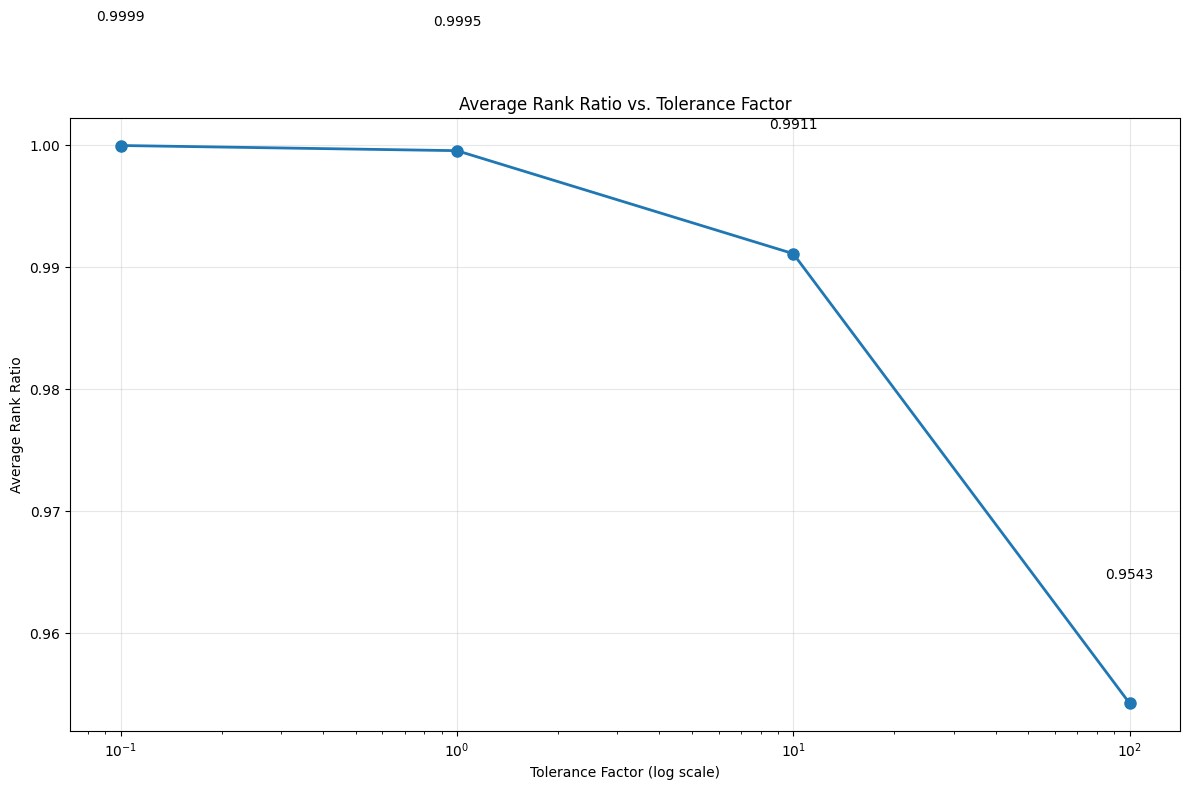

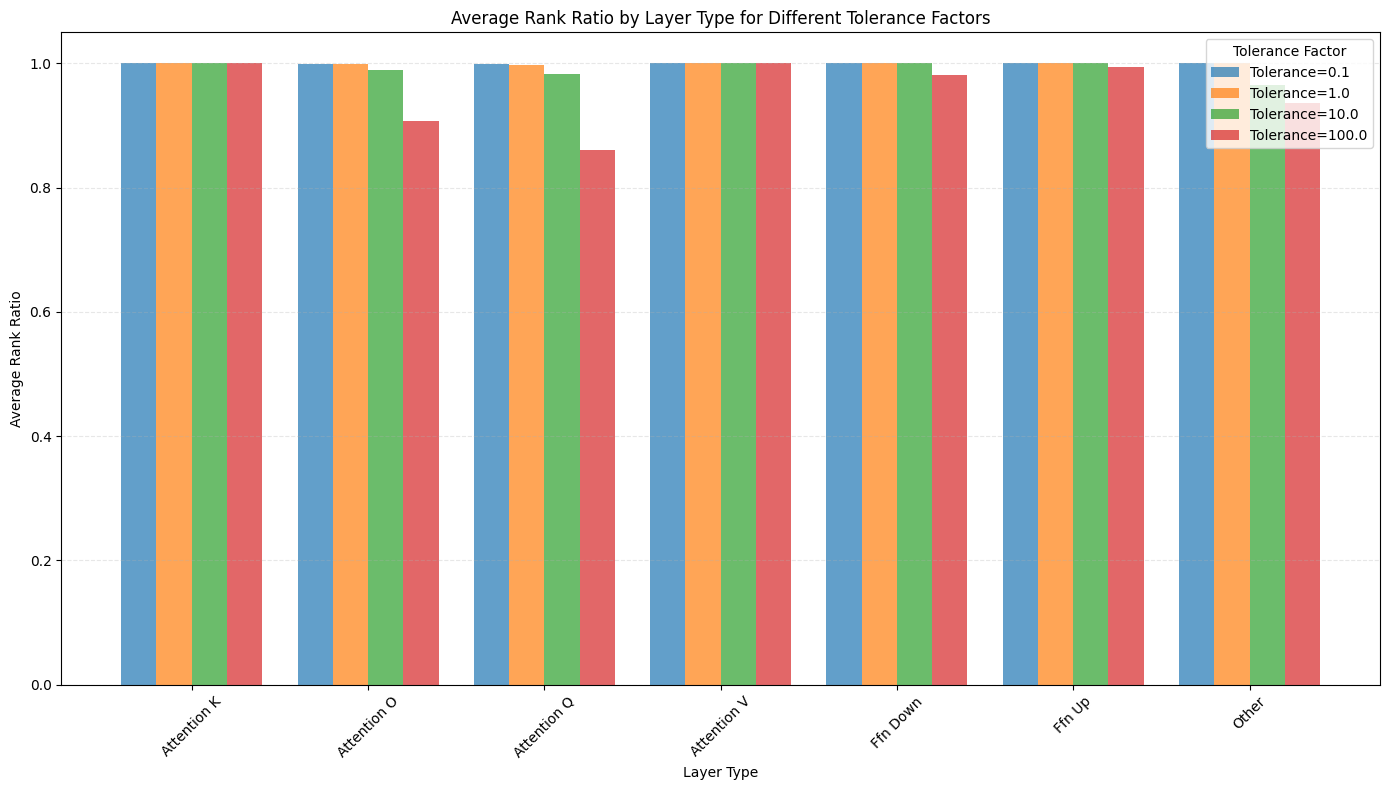

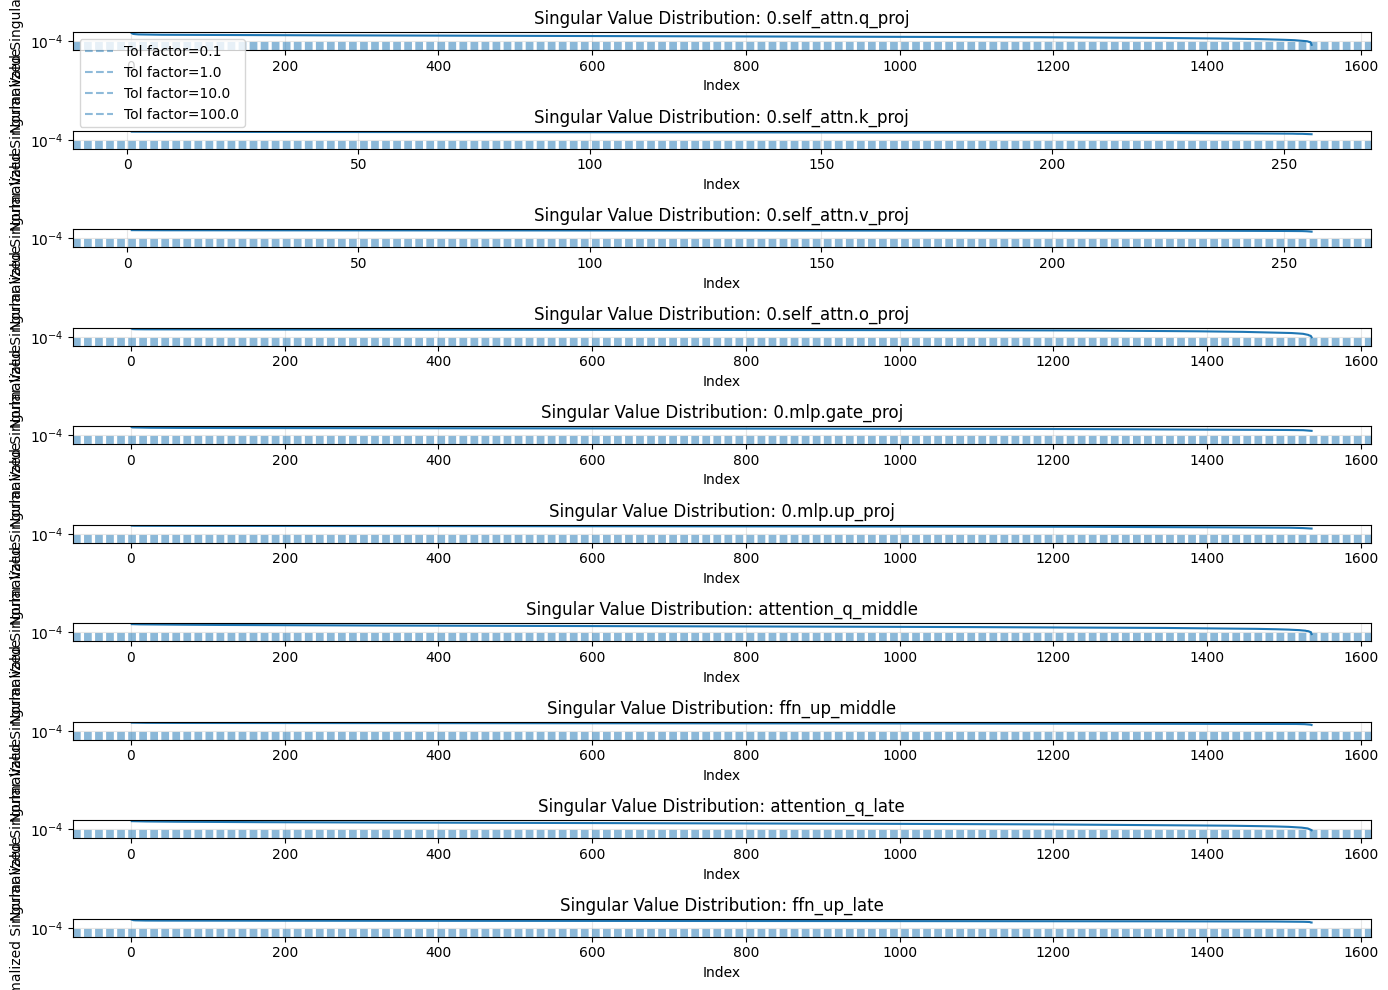

<module 'matplotlib.pyplot' from '/home/valentin/projects/research/low_rank_llm/.venv/lib/python3.12/site-packages/matplotlib/pyplot.py'>

In [13]:
# 1. Run the analysis with multiple tolerance factors:
results = analyze_with_multiple_tolerances(
    "Qwen/Qwen2.5-1.5B-Instruct", 
    batch_size=5,
    tolerance_factors=[0.1, 1.0, 10.0, 100.0],
    results_dir="rank_analysis_results"
)

# 2. Visualize the results:
visualize_tolerance_comparison(results_dir="rank_analysis_results")

In [1]:
import torch
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM
import gc
import numpy as np
import re
import time
import json
import os
from collections import defaultdict

def analyze_sparseness(model_name="Qwen/Qwen2.5-1.5B-Instruct", 
                     batch_size=5,
                     thresholds=[1e-5, 1e-4, 1e-3, 1e-2, 1e-1],
                     results_dir="sparseness_analysis_results"):
    """
    Analyze the sparseness of linear layers in the model.
    
    Args:
        model_name: Name or path of the model to analyze
        batch_size: Number of layers to process before clearing memory
        thresholds: List of threshold values for considering a weight as zero
        results_dir: Directory to save results
        
    Returns:
        Dictionary with sparseness analysis results
    """
    # Create results directory if it doesn't exist
    os.makedirs(results_dir, exist_ok=True)
    print(f"Saving results to directory: {results_dir}")
    
    print(f"Loading model: {model_name}")
    start_time = time.time()
    
    # Try loading the model
    try:
        model = AutoModelForCausalLM.from_pretrained(
            model_name,
            torch_dtype=torch.float16
        )
        print("Model loaded successfully")
    except Exception as e:
        print(f"Error loading model: {str(e)}")
        return None
    
    # Collect all linear layers
    linear_layers = []
    print("Collecting all linear layers...")
    for name, module in model.named_modules():
        if isinstance(module, torch.nn.Linear):
            linear_layers.append((name, module))
    
    total_layers = len(linear_layers)
    print(f"Found {total_layers} linear layers to analyze")
    
    # Create batches
    batches = [linear_layers[i:i + batch_size] for i in range(0, len(linear_layers), batch_size)]
    print(f"Processing in {len(batches)} batches of up to {batch_size} layers each")
    
    # Initialize results dictionary - organized by threshold
    all_results = {}
    
    # Track overall model statistics
    total_weights = 0
    total_sparse_weights = {threshold: 0 for threshold in thresholds}
    
    # Keep some sample weight distributions for plotting histograms
    sample_distributions = {}
    
    # Process each batch
    for batch_idx, batch in enumerate(batches):
        print(f"\nProcessing batch {batch_idx+1}/{len(batches)}")
        batch_results = {}
        
        # Process each layer in the batch
        for idx, (name, module) in enumerate(batch):
            print(f"Processing layer {idx+1}/{len(batch)}: {name}")
            try:
                # Access the weight directly
                weight = module.weight
                
                # Get matrix dimensions
                out_features, in_features = weight.shape
                weight_count = out_features * in_features
                
                # Convert to CPU and float32 for analysis if needed
                if weight.dtype == torch.float16:
                    weight_abs = weight.abs().to(torch.float32)
                else:
                    weight_abs = weight.abs()
                
                # Flatten the weight matrix
                flat_weights = weight_abs.view(-1).detach().cpu().numpy()
                
                # Identify layer type
                layer_type = "other"
                if 'q_proj' in name:
                    layer_type = "attention_q"
                elif 'k_proj' in name:
                    layer_type = "attention_k"
                elif 'v_proj' in name:
                    layer_type = "attention_v"
                elif 'o_proj' in name:
                    layer_type = "attention_o"
                elif 'up_proj' in name or 'intermediate' in name or 'fc1' in name:
                    layer_type = "ffn_up"
                elif 'down_proj' in name or 'output' in name or 'fc2' in name:
                    layer_type = "ffn_down"
                
                # Extract layer number if possible
                layer_num = None
                match = re.search(r'layers\.(\d+)', name)
                if match:
                    layer_num = int(match.group(1))
                
                # Store basic layer info
                layer_info = {
                    'layer_type': layer_type,
                    'layer_num': layer_num,
                    'out_features': int(out_features),
                    'in_features': int(in_features),
                    'weight_count': int(weight_count),
                    'weight_stats': {
                        'min': float(flat_weights.min()),
                        'max': float(flat_weights.max()),
                        'mean': float(flat_weights.mean()),
                        'median': float(np.median(flat_weights)),
                        'std': float(flat_weights.std())
                    },
                    'sparseness': {}
                }
                
                # Compute sparseness for each threshold
                for threshold in thresholds:
                    sparse_count = np.sum(flat_weights < threshold)
                    sparseness = sparse_count / weight_count
                    
                    # Update layer results
                    layer_info['sparseness'][str(threshold)] = {
                        'count': int(sparse_count),
                        'ratio': float(sparseness)
                    }
                    
                    # Update total counts
                    total_sparse_weights[threshold] += sparse_count
                
                # Update total weight count
                total_weights += weight_count
                
                # Sample a few layers for weight distribution visualization
                # Choose representative layers from different types and positions
                is_sampled = False
                if layer_type not in sample_distributions and len(sample_distributions) < 6:
                    sample_distributions[name] = {'weights': flat_weights, 'type': layer_type}
                    is_sampled = True
                elif layer_type in ['attention_q', 'ffn_up'] and layer_num is not None:
                    if layer_num == 0 and f"{layer_type}_early" not in sample_distributions:
                        sample_distributions[f"{layer_type}_early"] = {'weights': flat_weights, 'type': layer_type}
                        is_sampled = True
                    elif layer_num == model.config.num_hidden_layers // 2 and f"{layer_type}_middle" not in sample_distributions:
                        sample_distributions[f"{layer_type}_middle"] = {'weights': flat_weights, 'type': layer_type}
                        is_sampled = True
                    elif layer_num == model.config.num_hidden_layers - 1 and f"{layer_type}_late" not in sample_distributions:
                        sample_distributions[f"{layer_type}_late"] = {'weights': flat_weights, 'type': layer_type}
                        is_sampled = True
                
                if is_sampled:
                    print(f"  Sampled weight distribution for visualization")
                
                # Print results for this layer
                print(f"  Weight stats - Min: {layer_info['weight_stats']['min']:.6f}, Max: {layer_info['weight_stats']['max']:.6f}, Mean: {layer_info['weight_stats']['mean']:.6f}")
                for threshold in thresholds:
                    sparseness = layer_info['sparseness'][str(threshold)]['ratio']
                    print(f"  Threshold {threshold:.6f}: {sparseness:.4f} ({sparseness*100:.2f}% sparse)")
                
                # Store this layer's results
                batch_results[name] = layer_info
                    
            except Exception as e:
                print(f"Error analyzing layer {name}: {str(e)}")
        
        # Update all_results with this batch's results
        all_results.update(batch_results)
        
        # Save interim results after each batch
        interim_filename = os.path.join(results_dir, f"interim_batch_{batch_idx+1}.json")
        with open(interim_filename, 'w') as f:
            json.dump(all_results, f, indent=2)
        print(f"Saved interim results to {interim_filename}")
        
        # Print batch summary
        print("Batch summary:")
        batch_sparseness = {threshold: [] for threshold in thresholds}
        
        for layer_name, layer_data in batch_results.items():
            for threshold in thresholds:
                batch_sparseness[threshold].append(
                    layer_data['sparseness'][str(threshold)]['ratio']
                )
        
        for threshold in thresholds:
            avg_sparseness = sum(batch_sparseness[threshold]) / len(batch_sparseness[threshold])
            print(f"  Threshold {threshold:.6f}: Average sparseness {avg_sparseness:.4f} ({avg_sparseness*100:.2f}%)")
        
        # Force garbage collection between batches
        gc.collect()
        torch.cuda.empty_cache() if torch.cuda.is_available() else None
    
    # Save weight distribution samples for visualization
    if sample_distributions:
        # Convert numpy arrays to lists for JSON serialization
        samples_json = {}
        for name, data in sample_distributions.items():
            # Store the histogram data instead of raw weights
            hist, bin_edges = np.histogram(data['weights'], bins=100, range=(0, 0.1))
            samples_json[name] = {
                'type': data['type'],
                'histogram': hist.tolist(),
                'bin_edges': bin_edges.tolist(),
                'stats': {
                    'min': float(data['weights'].min()),
                    'max': float(data['weights'].max()),
                    'mean': float(data['weights'].mean()),
                    'median': float(np.median(data['weights'])),
                    'std': float(data['weights'].std())
                }
            }
        
        sample_filename = os.path.join(results_dir, "weight_distribution_samples.json")
        with open(sample_filename, 'w') as f:
            json.dump(samples_json, f, indent=2)
        print(f"Saved weight distribution samples to {sample_filename}")
    
    # Compute overall model sparseness
    model_sparseness = {}
    for threshold in thresholds:
        overall_sparseness = total_sparse_weights[threshold] / total_weights
        model_sparseness[str(threshold)] = {
            'total_weights': int(total_weights),
            'sparse_weights': int(total_sparse_weights[threshold]),
            'ratio': float(overall_sparseness)
        }
    
    # Add model-level statistics to results
    all_results['__model_stats__'] = {
        'total_weights': int(total_weights),
        'total_layers': total_layers,
        'sparseness': model_sparseness
    }
    
    # Free model memory
    del model
    gc.collect()
    torch.cuda.empty_cache() if torch.cuda.is_available() else None
    
    # Save final results
    final_filename = os.path.join(results_dir, "complete_results.json")
    with open(final_filename, 'w') as f:
        json.dump(all_results, f, indent=2)
    print(f"Saved complete results to {final_filename}")
    
    # Write model info to a text file
    model_info_filename = os.path.join(results_dir, "model_info.txt")
    with open(model_info_filename, 'w') as f:
        f.write(f"Model: {model_name}\n")
        f.write(f"Analysis date: {time.strftime('%Y-%m-%d %H:%M:%S')}\n")
        f.write(f"Sparseness thresholds: {thresholds}\n")
        f.write(f"Total layers analyzed: {total_layers}\n")
        f.write(f"Total weight parameters: {total_weights:,}\n")
        
        f.write("\nOverall model sparseness:\n")
        for threshold in thresholds:
            overall_sparseness = model_sparseness[str(threshold)]['ratio']
            sparse_count = model_sparseness[str(threshold)]['sparse_weights']
            f.write(f"  Threshold {threshold:.6f}: {overall_sparseness:.6f} ({overall_sparseness*100:.2f}%), {sparse_count:,} weights\n")
        
        f.write(f"\nTotal analysis time: {time.time() - start_time:.2f} seconds\n")
    
    # Print total time
    elapsed_time = time.time() - start_time
    print(f"Total analysis time: {elapsed_time:.2f} seconds")
    
    return all_results

def visualize_sparseness(results_file=None, results_dir="sparseness_analysis_results"):
    """
    Create visualizations from sparseness analysis results.
    
    Args:
        results_file: Path to the JSON file with analysis results
        results_dir: Directory where results are stored
    """
    # If no specific file is provided, use the default one in the results directory
    if results_file is None:
        results_file = os.path.join(results_dir, "complete_results.json")
    
    # Make sure the results directory exists
    os.makedirs(results_dir, exist_ok=True)
    
    # Load results from file
    try:
        with open(results_file, 'r') as f:
            results = json.load(f)
        
        # Extract model stats
        if '__model_stats__' in results:
            model_stats = results.pop('__model_stats__')
            print(f"Loaded results for {model_stats['total_layers']} layers with {model_stats['total_weights']:,} total weights")
        else:
            print(f"Loaded results for {len(results)} layers")
            model_stats = None
    except Exception as e:
        print(f"Error loading results: {str(e)}")
        return
    
    # Get thresholds from the first layer's data
    first_layer = next(iter(results.values()))
    thresholds = [float(t) for t in first_layer['sparseness'].keys()]
    thresholds.sort()
    print(f"Thresholds: {thresholds}")
    
    # Plot 1: Overall model sparseness by threshold
    if model_stats and 'sparseness' in model_stats:
        plt.figure(figsize=(12, 8))
        
        threshold_values = []
        sparseness_values = []
        
        for threshold in sorted(model_stats['sparseness'].keys(), key=float):
            threshold_values.append(float(threshold))
            sparseness_values.append(model_stats['sparseness'][threshold]['ratio'])
        
        plt.plot(threshold_values, sparseness_values, 'o-', linewidth=2, markersize=8)
        plt.xscale('log')  # Log scale for thresholds
        
        for i, (thresh, sparse) in enumerate(zip(threshold_values, sparseness_values)):
            plt.text(thresh, sparse + 0.01, f"{sparse:.4f}", ha='center', va='bottom')
        
        plt.xlabel('Threshold Value (log scale)')
        plt.ylabel('Sparseness Ratio')
        plt.title('Overall Model Sparseness vs. Threshold')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig(os.path.join(results_dir, 'model_sparseness_by_threshold.png'), dpi=300, bbox_inches='tight')
        plt.show()
    
    # Plot 2: Sparseness by layer type for each threshold
    plt.figure(figsize=(14, 10))
    
    # Group by layer type
    type_sparseness = defaultdict(lambda: defaultdict(list))
    
    for layer_name, layer_data in results.items():
        layer_type = layer_data['layer_type']
        
        for threshold in thresholds:
            threshold_str = str(threshold)
            if threshold_str in layer_data['sparseness']:
                sparseness = layer_data['sparseness'][threshold_str]['ratio']
                type_sparseness[threshold][layer_type].append(sparseness)
    
    # Create subplots for each threshold
    num_thresholds = len(thresholds)
    cols = min(3, num_thresholds)
    rows = (num_thresholds + cols - 1) // cols  # Ceiling division
    
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5*rows))
    if num_thresholds == 1:
        axes = np.array([axes])  # Make sure axes is always a numpy array
    axes = axes.flatten()
    
    # Define colors for each layer type
    type_colors = {
        'attention_q': 'royalblue',
        'attention_k': 'cornflowerblue',
        'attention_v': 'lightblue',
        'attention_o': 'steelblue', 
        'ffn_up': 'salmon',
        'ffn_down': 'tomato',
        'other': 'gray'
    }
    
    for i, threshold in enumerate(thresholds):
        threshold_str = str(threshold)
        ax = axes[i]
        
        # Get all layer types for this threshold
        layer_types = sorted(type_sparseness[threshold].keys())
        
        # Calculate average sparseness for each type
        avg_sparseness = []
        for lt in layer_types:
            values = type_sparseness[threshold][lt]
            avg_sparseness.append(sum(values) / len(values))
        
        # Sort by average sparseness
        sorted_indices = np.argsort(avg_sparseness)
        sorted_types = [layer_types[i] for i in sorted_indices]
        sorted_values = [avg_sparseness[i] for i in sorted_indices]
        sorted_colors = [type_colors.get(t, 'gray') for t in sorted_types]
        
        # Plot bar chart
        bars = ax.bar(sorted_types, sorted_values, color=sorted_colors)
        
        # Add values on top of bars
        for j, value in enumerate(sorted_values):
            ax.text(j, value + 0.01, f"{value:.3f}", ha='center', va='bottom', rotation=0)
        
        # Format the axis
        ax.set_ylim(0, min(1.0, max(sorted_values) * 1.2))
        ax.set_title(f'Threshold = {threshold:.6f}')
        ax.set_xticks(range(len(sorted_types)))
        ax.set_xticklabels([t.replace('_', ' ').title() for t in sorted_types], rotation=45, ha='right')
        ax.grid(axis='y', linestyle='--', alpha=0.3)
    
    # Remove any unused subplots
    for i in range(num_thresholds, len(axes)):
        fig.delaxes(axes[i])
    
    plt.tight_layout()
    plt.savefig('sparseness_by_layer_type.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Plot 3: Sparseness by model depth (layer position)
    layer_nums = []
    layer_data_by_num = defaultdict(lambda: defaultdict(list))
    
    for layer_name, layer_data in results.items():
        layer_num = layer_data.get('layer_num')
        layer_type = layer_data.get('layer_type')
        
        if layer_num is not None:
            if layer_num not in layer_nums:
                layer_nums.append(layer_num)
            
            for threshold in thresholds:
                threshold_str = str(threshold)
                if threshold_str in layer_data['sparseness']:
                    sparseness = layer_data['sparseness'][threshold_str]['ratio']
                    layer_data_by_num[threshold][layer_num].append((layer_type, sparseness))
    
    if layer_nums:
        layer_nums.sort()
        
        # Create a separate plot for each threshold
        for threshold in thresholds:
            plt.figure(figsize=(14, 8))
            
            # For each layer type, plot its sparseness across layer depth
            layer_type_data = defaultdict(lambda: defaultdict(float))
            
            # Average sparseness by layer type and number
            for layer_num in layer_nums:
                data_points = layer_data_by_num[threshold][layer_num]
                for layer_type, sparseness in data_points:
                    if layer_type not in layer_type_data:
                        layer_type_data[layer_type] = {}
                    
                    if layer_num not in layer_type_data[layer_type]:
                        layer_type_data[layer_type][layer_num] = []
                    
                    layer_type_data[layer_type][layer_num].append(sparseness)
            
            # Plot each layer type as a separate line
            for layer_type in sorted(layer_type_data.keys()):
                x = []
                y = []
                
                for layer_num in sorted(layer_type_data[layer_type].keys()):
                    values = layer_type_data[layer_type][layer_num]
                    avg_sparseness = sum(values) / len(values)
                    
                    x.append(layer_num)
                    y.append(avg_sparseness)
                
                plt.plot(x, y, 'o-', label=layer_type.replace('_', ' ').title(), 
                         color=type_colors.get(layer_type, 'gray'))
            
            plt.xlabel('Layer Depth')
            plt.ylabel('Sparseness Ratio')
            plt.title(f'Sparseness vs. Layer Depth (Threshold={threshold:.6f})')
            plt.grid(True, alpha=0.3)
            plt.legend()
            
            plt.savefig(f'sparseness_by_depth_threshold_{threshold:.6f}.png', 
                      dpi=300, bbox_inches='tight')
            plt.show()
    
    # Plot 4: Weight distribution histograms
    # Try to load the weight distribution samples
    try:
        sample_file = os.path.join(results_dir, "weight_distribution_samples.json")
        with open(sample_file, 'r') as f:
            weight_samples = json.load(f)
        
        if weight_samples:
            # Create subplots for each sample
            num_samples = len(weight_samples)
            cols = min(2, num_samples)
            rows = (num_samples + cols - 1) // cols  # Ceiling division
            
            fig, axes = plt.subplots(rows, cols, figsize=(15, 5*rows))
            if num_samples == 1:
                axes = np.array([axes])  # Make sure axes is always a numpy array
            axes = axes.flatten()
            
            for i, (name, data) in enumerate(weight_samples.items()):
                if i >= len(axes):
                    break
                    
                ax = axes[i]
                
                # Extract histogram data
                hist = np.array(data['histogram'])
                bin_edges = np.array(data['bin_edges'])
                bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
                
                # Plot histogram
                ax.bar(bin_centers, hist, width=(bin_edges[1] - bin_edges[0]), 
                       alpha=0.7, color=type_colors.get(data['type'], 'gray'))
                
                # Add vertical lines for thresholds
                for threshold in thresholds:
                    if threshold <= 0.1:  # Only show thresholds in the plot range
                        ax.axvline(x=threshold, color='red', linestyle='--', 
                                   label=f'Threshold={threshold:.6f}')
                
                # Make shorter name for display
                display_name = name.split('.')[-3:] if '.' in name else name
                if isinstance(display_name, list):
                    display_name = '.'.join(display_name)
                
                ax.set_title(f'{display_name} ({data["type"].replace("_", " ").title()})')
                ax.set_xlabel('Weight Absolute Value')
                ax.set_ylabel('Count')
                ax.set_xlim(0, 0.1)  # Focus on small weights
                
                # Only show legend on first subplot
                if i == 0:
                    ax.legend()
            
            # Remove any unused subplots
            for i in range(num_samples, len(axes)):
                fig.delaxes(axes[i])
            
            plt.tight_layout()
            plt.savefig('weight_distributions.png', dpi=300, bbox_inches='tight')
            plt.show()
    
    except Exception as e:
        print(f"Could not plot weight distributions: {str(e)}")
    
    return plt

# Example usage:
# 1. Run the sparseness analysis:
# results = analyze_sparseness(
#     "Qwen/Qwen2.5-1.5B-Instruct", 
#     batch_size=5,
#     thresholds=[1e-5, 1e-4, 1e-3, 1e-2, 1e-1],
#     results_dir="sparseness_analysis_results"
# )
#
# 2. Visualize the results:
# visualize_sparseness(results_dir="sparseness_analysis_results")

/home/valentin/projects/research/low_rank_llm/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Saving results to directory: sparseness_analysis_results
Loading model: Qwen/Qwen2.5-1.5B-Instruct


Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


Model loaded successfully
Found 197 linear layers to analyze
Processing in 40 batches of up to 5 layers each

Processing batch 1/40
Processing layer 1/5: model.layers.0.self_attn.q_proj
  Sampled weight distribution for visualization
  Weight stats - Min: 0.000000, Max: 1.406250, Mean: 0.033141
  Threshold 0.000010: 0.0003 (0.03% sparse)
  Threshold 0.000100: 0.0027 (0.27% sparse)
  Threshold 0.001000: 0.0272 (2.72% sparse)
  Threshold 0.010000: 0.2570 (25.70% sparse)
  Threshold 0.100000: 0.9491 (94.91% sparse)
Processing layer 2/5: model.layers.0.self_attn.k_proj
  Sampled weight distribution for visualization
  Weight stats - Min: 0.000000, Max: 0.433594, Mean: 0.042751
  Threshold 0.000010: 0.0001 (0.01% sparse)
  Threshold 0.000100: 0.0016 (0.16% sparse)
  Threshold 0.001000: 0.0172 (1.72% sparse)
  Threshold 0.010000: 0.1673 (16.73% sparse)
  Threshold 0.100000: 0.9204 (92.04% sparse)
Processing layer 3/5: model.layers.0.self_attn.v_proj
  Sampled weight distribution for visualiz

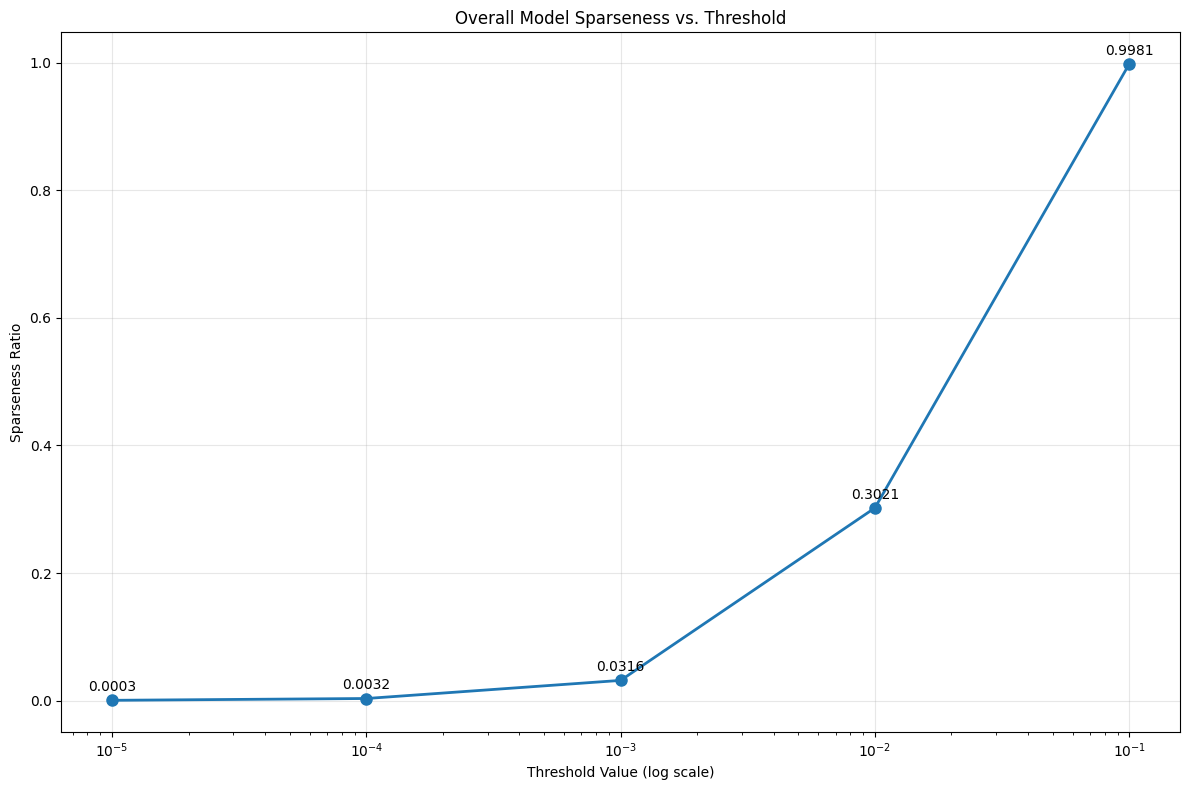

/tmp/ipykernel_81670/4090002343.py:420: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


<Figure size 1400x1000 with 0 Axes>

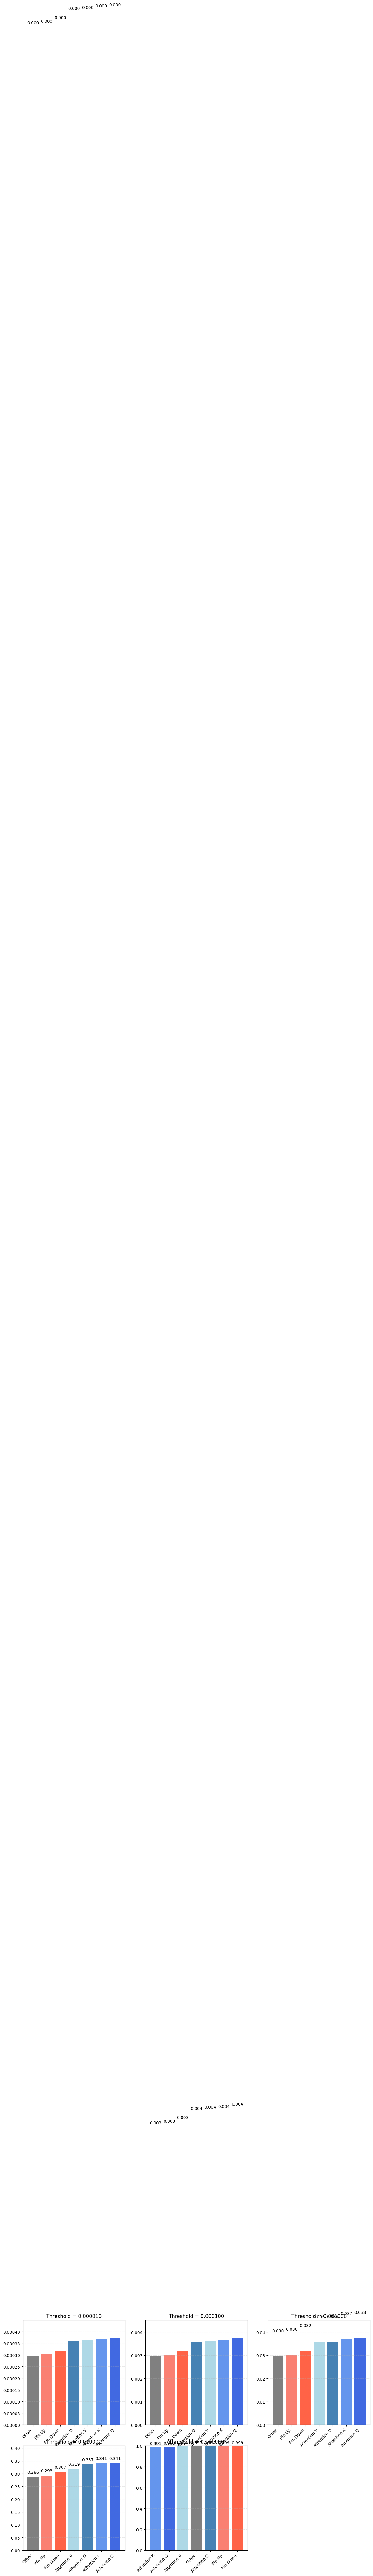

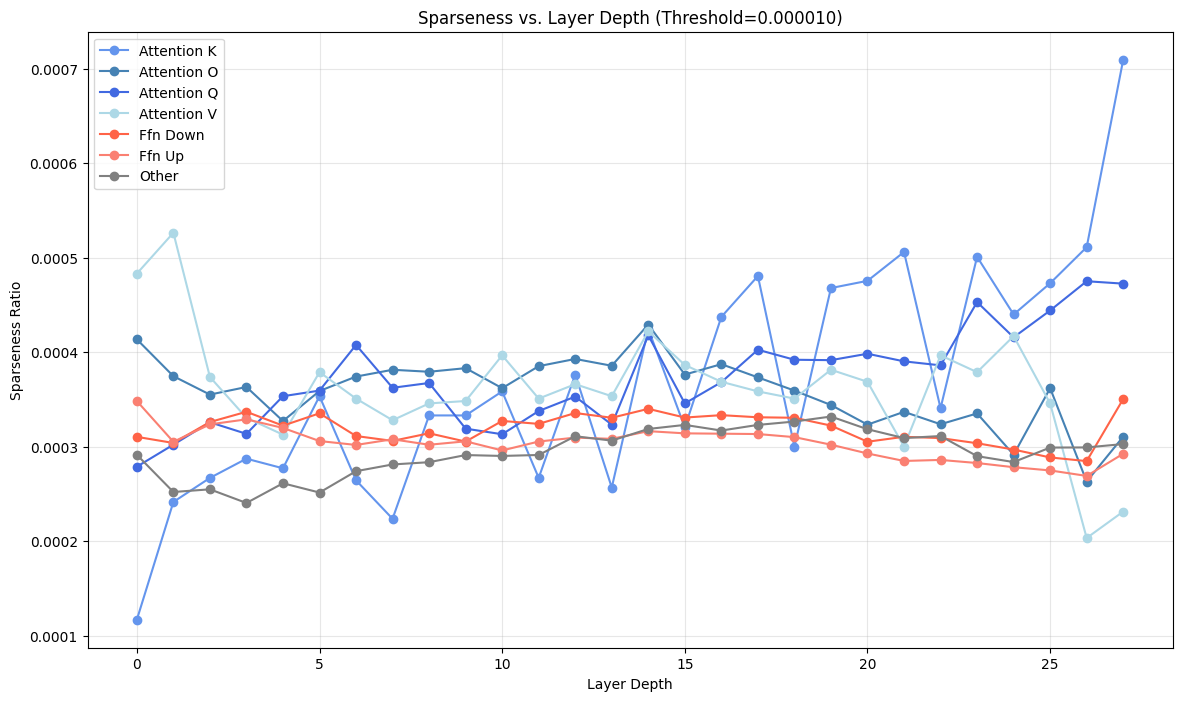

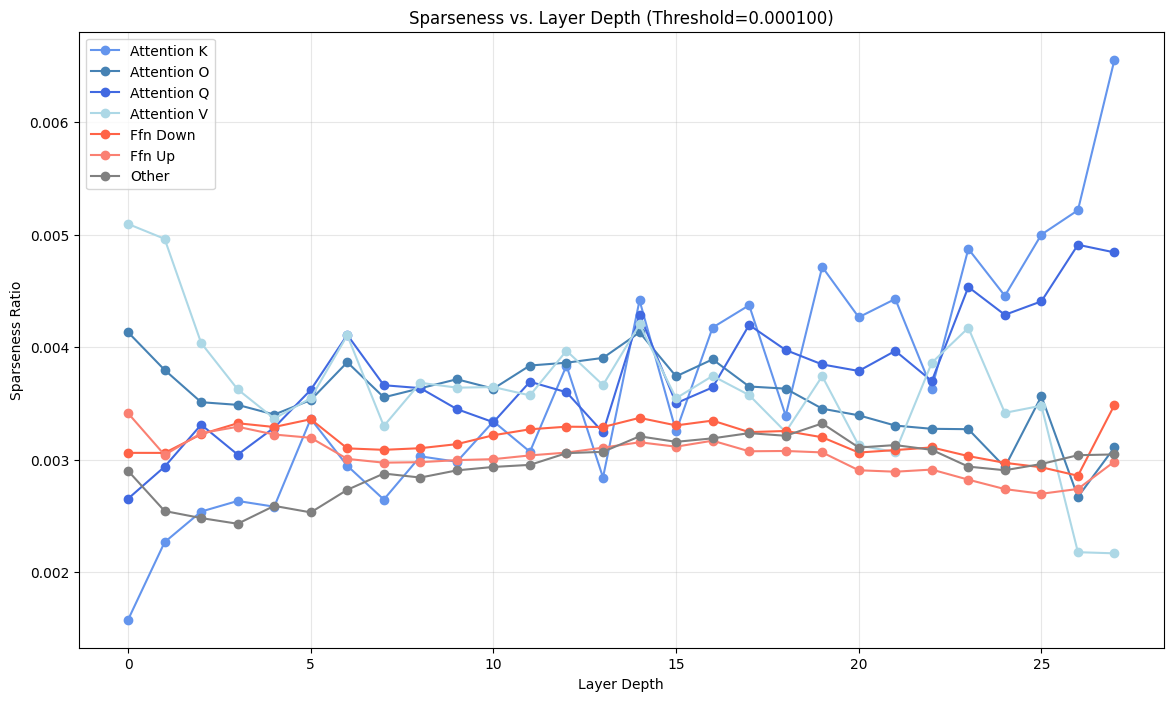

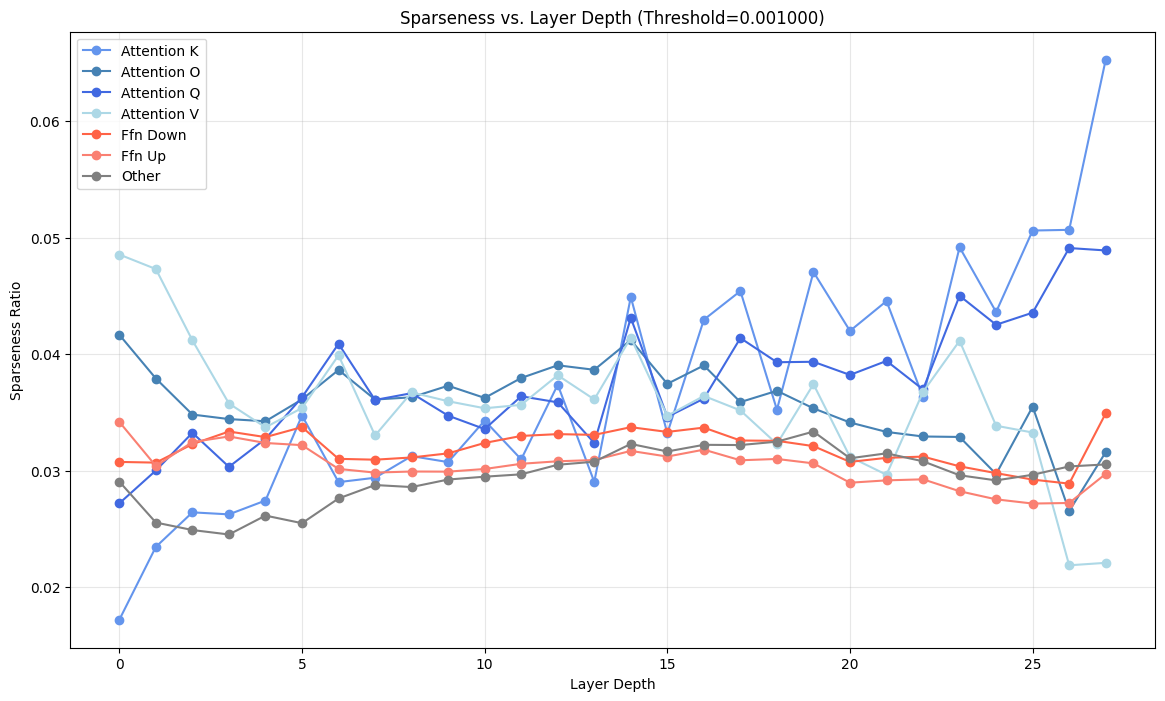

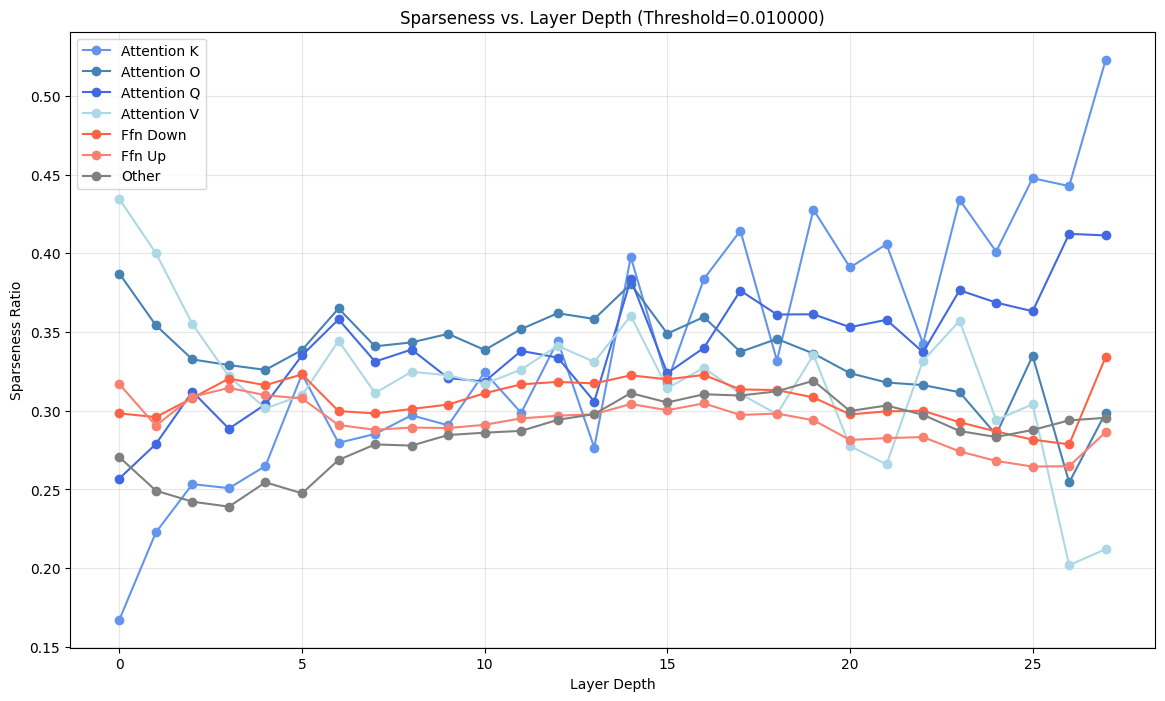

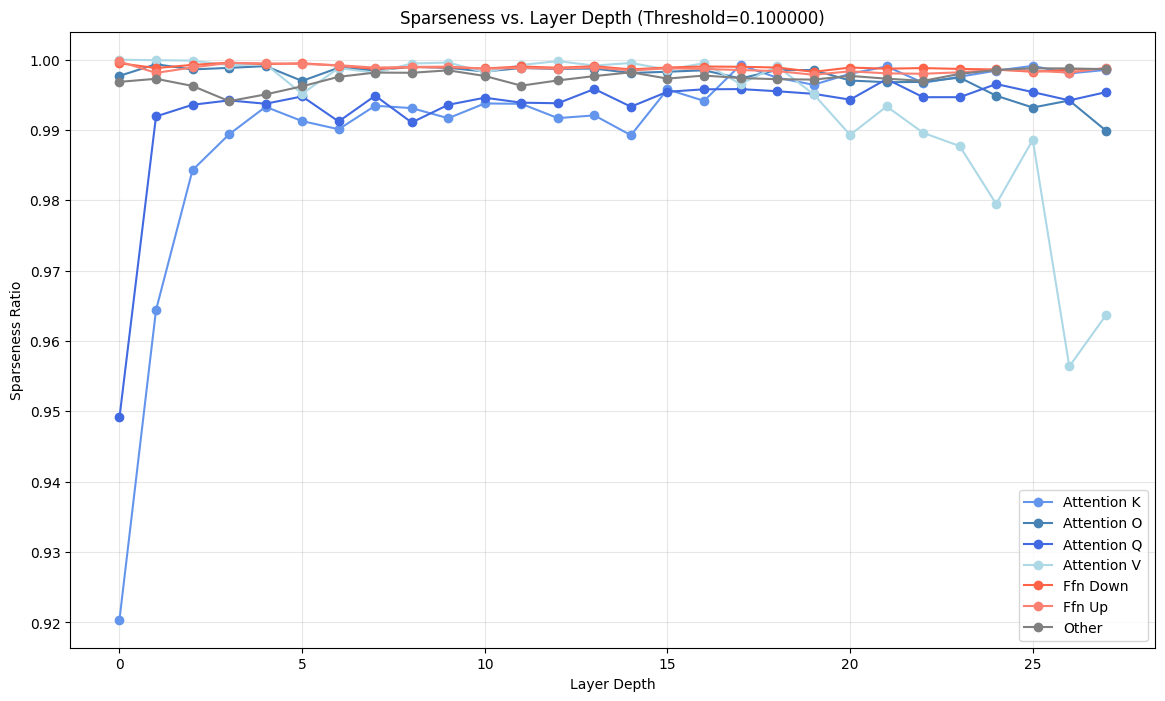

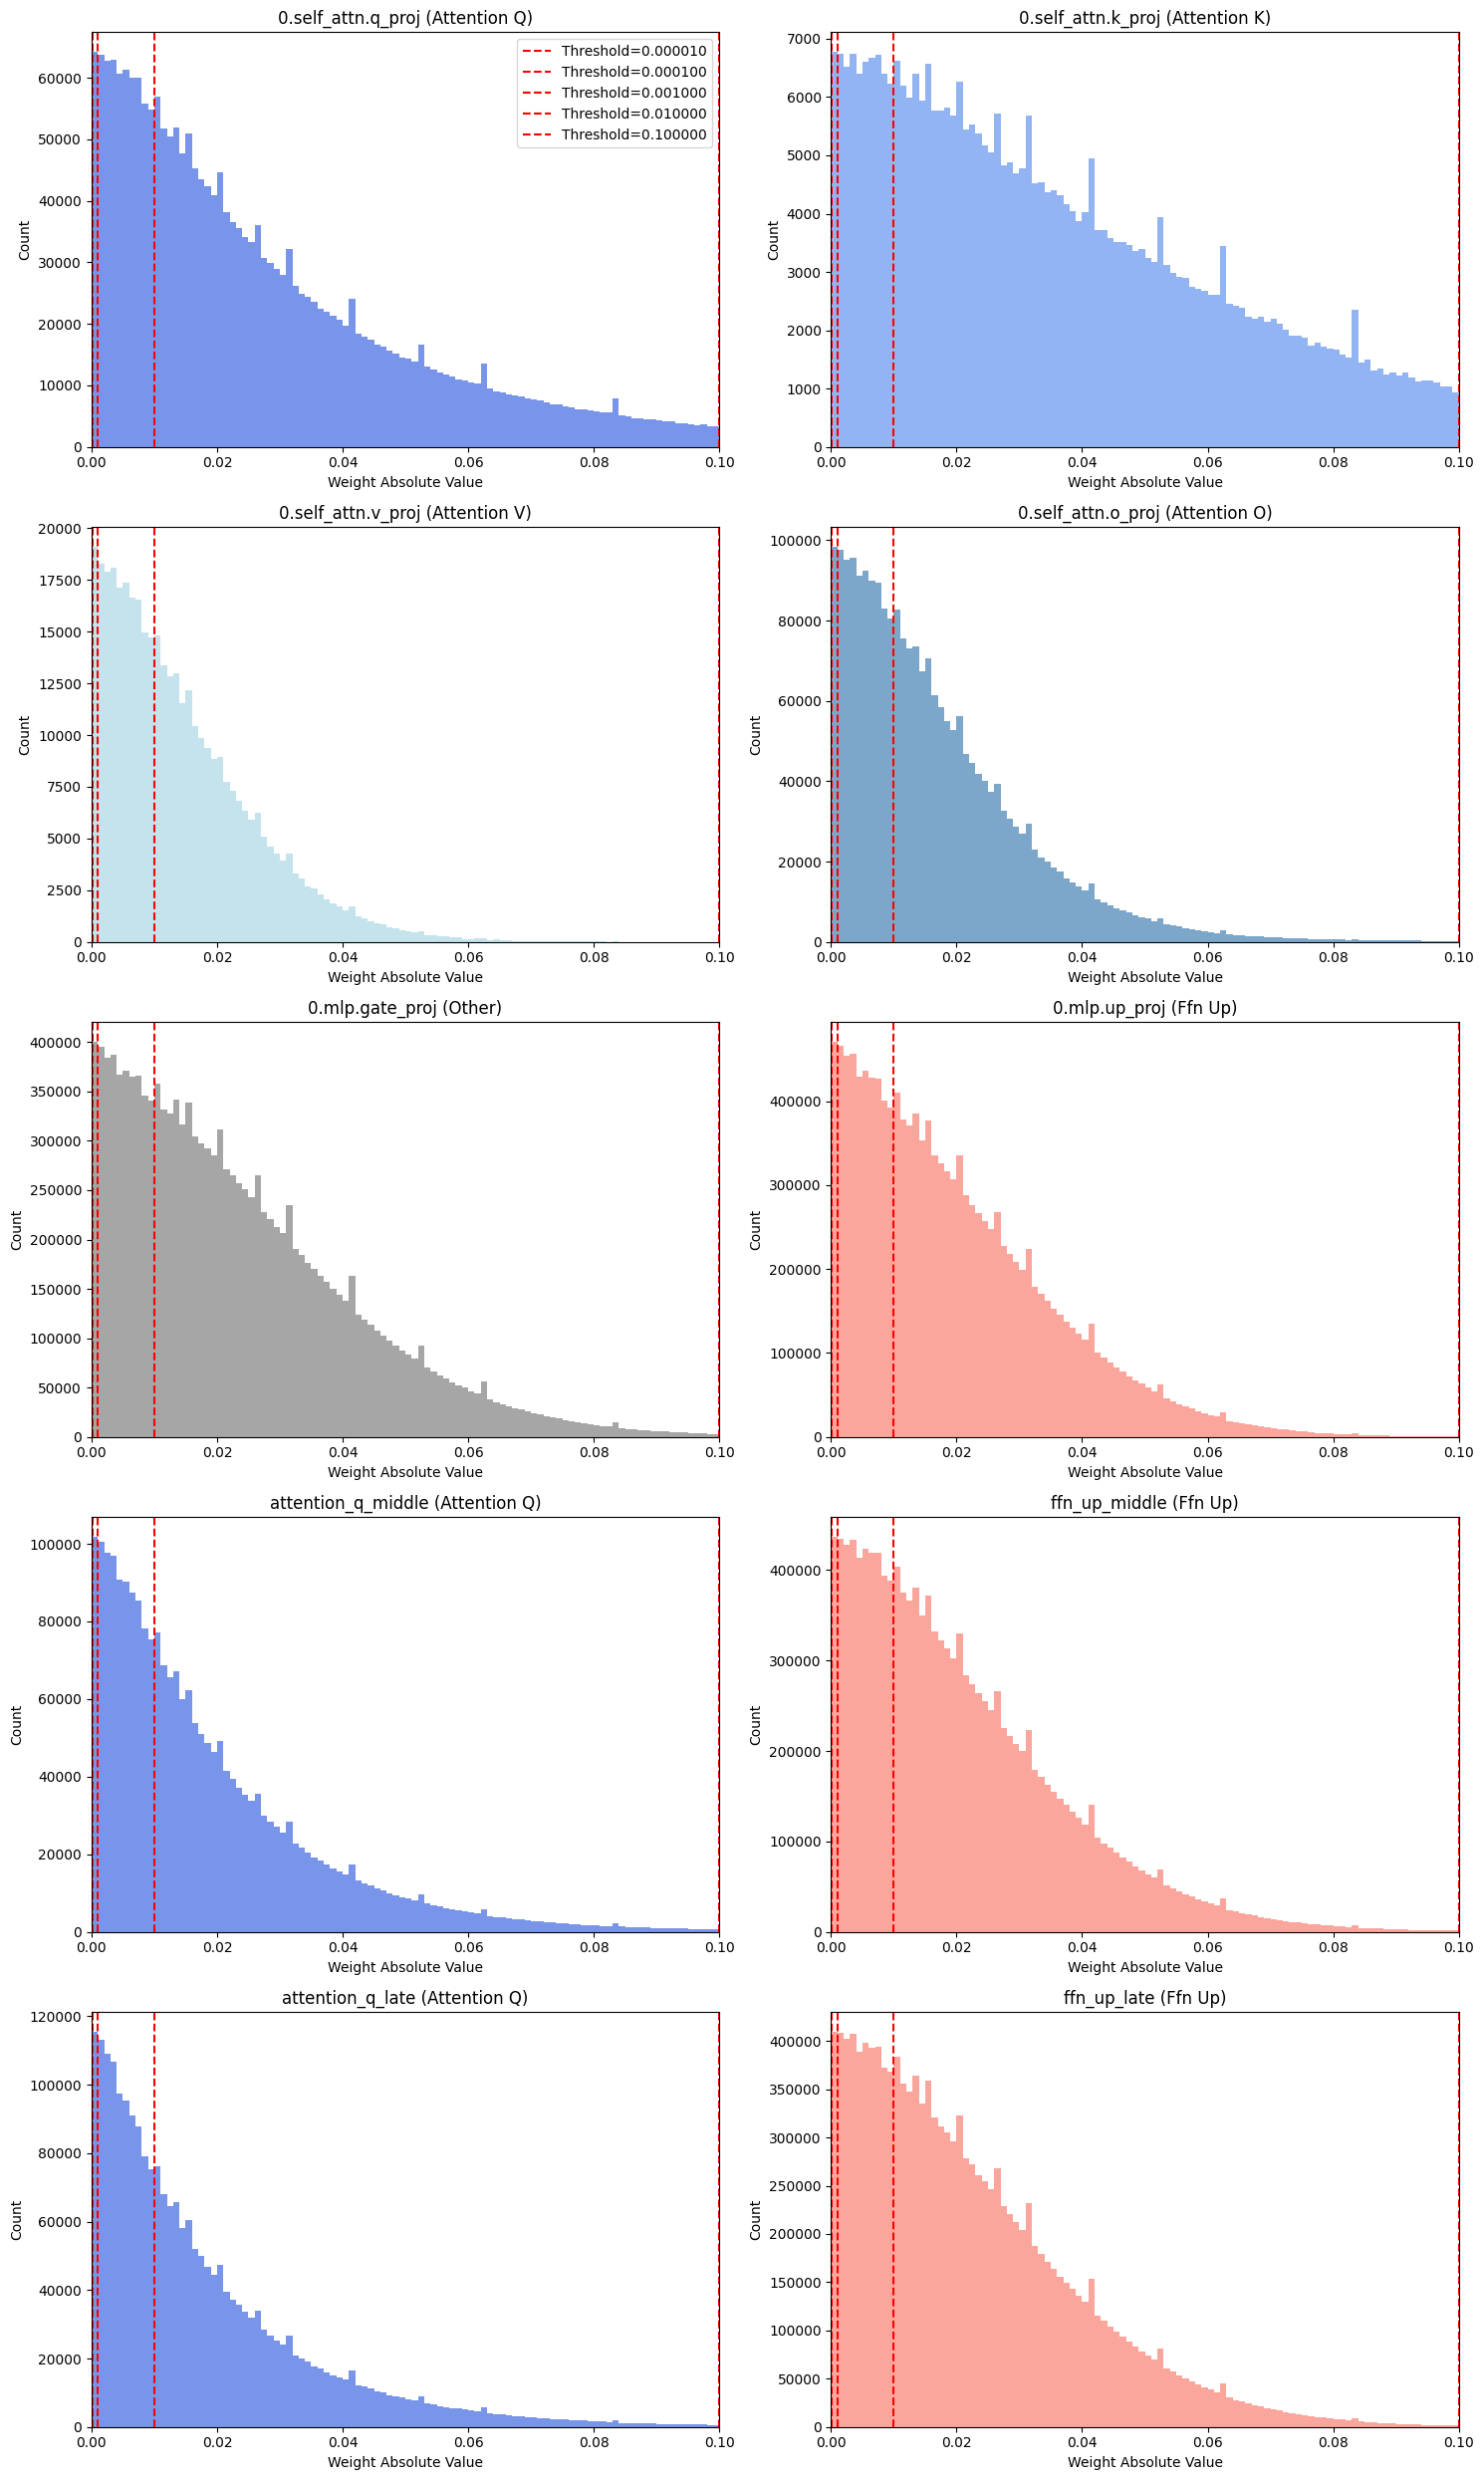

<module 'matplotlib.pyplot' from '/home/valentin/projects/research/low_rank_llm/.venv/lib/python3.12/site-packages/matplotlib/pyplot.py'>

In [2]:
# Example usage:
# 1. Run the sparseness analysis:
results = analyze_sparseness(
    "Qwen/Qwen2.5-1.5B-Instruct", 
    batch_size=5,
    thresholds=[1e-5, 1e-4, 1e-3, 1e-2, 1e-1],
    results_dir="sparseness_analysis_results"
)
#
# 2. Visualize the results:
visualize_sparseness(results_dir="sparseness_analysis_results")

Citations

Li, Y., Yu, Y., Zhang, Q., Liang, C., He, P., Chen, W., & Zhao, T. (2023). LoSparse: Structured Compression of Large Language Models based on Low-Rank and Sparse Approximation. https://arxiv.org/abs/2306.11222

Frankle, J., & Carbin, M. (2019). The lottery ticket hypothesis: Finding sparse, trainable neural networks (arXiv:1803.03635v5). Retrieved from https://arxiv.org/abs/1803.03635